In [1]:
# Librerias
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.model_selection import train_test_split

## 2. Mi Primera DCCasa

Antes del código, las veces que se usó inteligencia artificial como apoyo para el desarrollo de la tarea sigue la normativa del curso y de la entrega, será comentado en el código con unos corchetes, ejemplo: 'Uso de IA [1]'. Luego al final del archivo se explicará el prompt utilizado y cómo se manejó la respuesta.

### 2.3.1 Análisis exploratorio de Datos

A continuación se analizará la distribución de la variable objetivo **PRECIO_EN_UF**, se expondrá la existencia de datos faltantes en el dataset, se estudiará la correlación e importancia de diversas variables con respecto al precio entre otros posibles análisis presentados en formato gráfico.

In [2]:
# Precio en UF

# Primero cargamos el dataset y vemos como procederemos a limpiar
# El skip permite que pandas se salte lineas erróneas (Uso de IA [1])
# df = pd.read_csv('propiedades.csv', on_bad_lines='skip')

# La línea anterior la tengo así por que abrí el ipynb en colab y subía el csv,
# Si se ve en colab hay que subir los datos y se puede usar lo anterior
df = pd.read_csv(r'Datos Tarea 2\propiedades.csv', on_bad_lines='skip')
df.head()


,id,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,direccion,direccion_2,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
0,4987109,2,"Estupendo departamento, Orientación Nor-orient...",3,2,130.0,140.0,AMERICO VESPUCIO FRANCISCO DE AGUIRRE,Vitacura ...,306,43,13,2,0.0,180000.0,NaN,2.0,f,NaN,11100.000000
1,5632624,3,"ID 27944 EXCELENTE PROPIEDAD COMERCIAL, corres...",7,3,207.0,350.0,LOS OLMOS,Macul ...,292,43,13,2,0.0,0.0,NaN,0.0,f,NaN,8300.000000
2,4061055,2,DISPONIBLE!\nSe vende amplio y luminoso depart...,3,2,90.0,0.0,SECTOR METRO PRÍNCIPE DE GALES,La Reina ...,287,43,13,2,0.0,95000.0,NaN,1.0,f,1.0,5006.139010
3,3932577,2,Excelente departamento con inmejorable ubicaci...,2,3,65.0,0.0,Manuel Montt/Simón Bolivar,ÑUÑOA ...,294,43,13,2,0.0,0.0,NaN,1.0,f,NaN,4822.120381
4,5439664,2,Departamento muy bien ubicado y con buena vist...,3,2,140.0,200.0,Ex rotonda Perez Zujovic/Lateral Kennedy,Vitacura ...,306,43,13,2,0.0,275000.0,NaN,0.0,f,NaN,10490.000000


Notamos que para el entrenamiento del modelo el **id** no sirve de nada para el entrenamiento del modelo por lo que podemos eliminar esta columna, al igual, solamente mirando el encabezado del dataframe notamos que hay datos nulos en la columna de **piso**, por lo que después de ser revisados también se podría eliminar. Finalmente en la columna de **year** también se ven muchos datos que son 0, por lo que se puede ver si se elimina esta columna o se cambian los 0 por algún dato. Esto se desarrollará en la sección **2.3.2. Procesamiento de datos**.

Veamos la columna de nuestra variable objetivo:

In [3]:
df['precio_en_uf']

0        11100.000000
1         8300.000000
2         5006.139010
3         4822.120381
4        10490.000000
             ...     
20891     4600.000000
20892     4289.500298
20893     2793.320409
20894    12500.000000
20895     2881.925303
Name: precio_en_uf, Length: 20896, dtype: float64

In [4]:
# Convertimos los datos en un array para poder manipular / plotear
presio = df['precio_en_uf'].values
print(f'\nArray de numpy del precio: {presio}')


Array de numpy del precio: [11100.          8300.          5006.13900973 ...  2793.32040909
 12500.          2881.92530345]


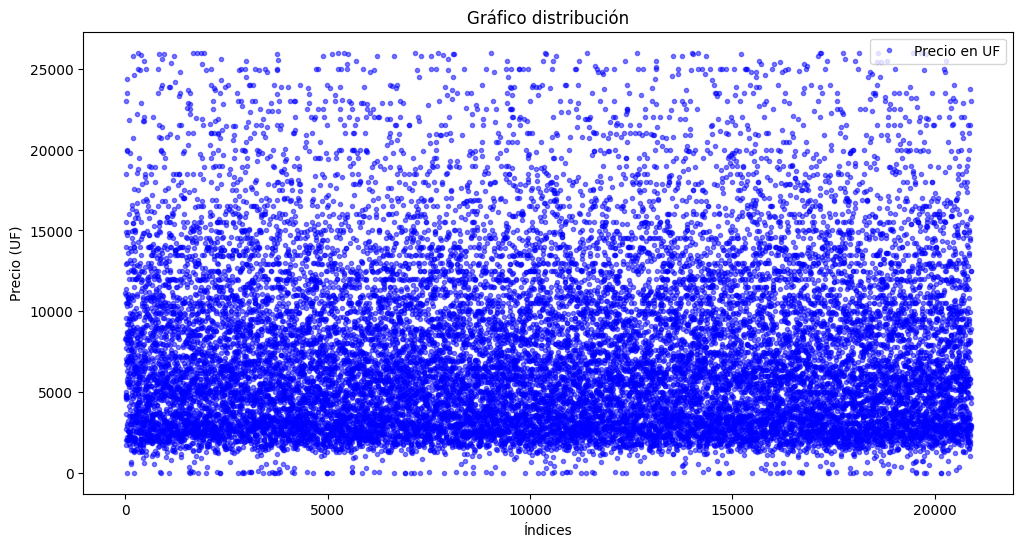

In [5]:
#Vamos a graficar los resultados de nuestro dato para ver su distribución:

fig, axs = plt.subplots(1, 1, figsize=(12, 6))
# Puntos
axs.plot(presio, marker='.', linestyle='none', color='blue', alpha=0.5)

axs.legend(['Precio en UF'])
axs.set_title('Gráfico distribución')
axs.set_xlabel('Índices')
axs.set_ylabel('Precio (UF)')

plt.show()

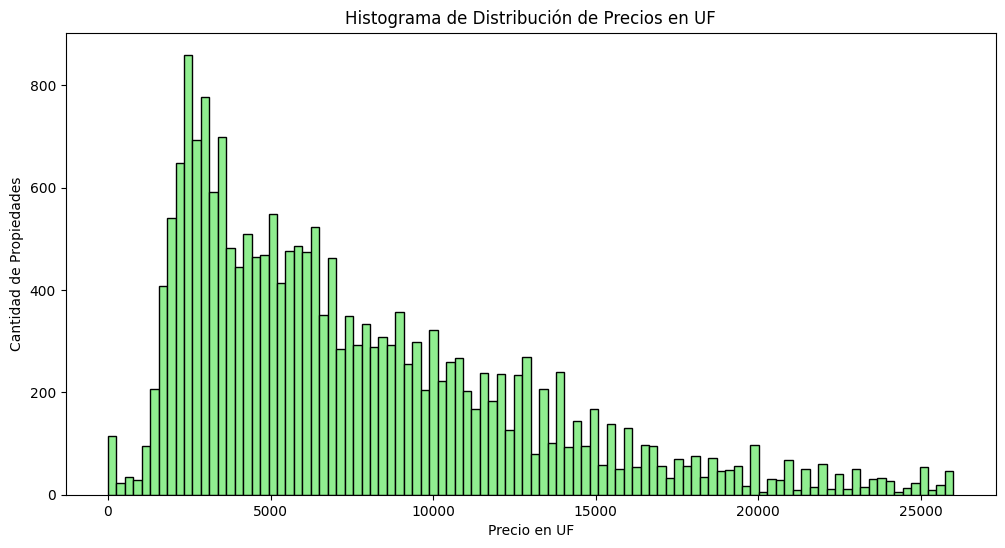

In [6]:
# Ahora hacemos un histograma
fig, ax = plt.subplots(1, 1, figsize=(12, 6))
# Lo que hace bins es agrupar los datos en 100 grupos (bins)
ax.hist(presio, bins=100, color='lightgreen', edgecolor='black')

ax.set_title('Histograma de Distribución de Precios en UF')
ax.set_xlabel('Precio en UF')
ax.set_ylabel('Cantidad de Propiedades')

plt.show()

Referencia del histograma:
Matplotlib. (s.f.). matplotlib.pyplot.hist. https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html

In [7]:
# Finalmente saquemos otros datos de nuestra columna
print(f"Valor máximo: {df['precio_en_uf'].max()} UF\n")
print(f"Valor mínimo: {df['precio_en_uf'].min()} UF\n")
print(f"Valor modal: {df['precio_en_uf'].mode()[0]} UF\n") # -> ese [0] es para imprimir solo la moda.
print(f"Valor promedio: {df['precio_en_uf'].mean()} UF\n")

Valor máximo: 26000.0 UF

Valor mínimo: 0.0004079076230147 UF

Valor modal: 10500.0 UF

Valor promedio: 7583.554467841225 UF



Del gráfico de dispersión y del histograma podemos ver que los datos se aglomeran entre 2000 - 7000 UF, siendo los datos entre 2000 - 3000 UF los que más se repiten. A pesar de lo anterior el promedio del dataset es de 7584 UF, lo cual indica la presencia de valores extremos (altos) que hacen que el promedio se desplace a la derecha. En efecto, aunque el valor mínimo es de prácticamente 0 UF (luego se verá si se limpian estos datos), el valor máximo es de **26000.0 UF** lo cual se aleja mucho del promedio y del rango modal que se ve a simple vista.

Otra cosa a considerar es que la moda es el valor exacto que más se repite pero no está muy correlacionado con los gráficos. Uno esperaría que esté en el rango 2000 - 3000 viéndo a simple vista el histograma pero el valor de la moda es de **10500 UF**, por lo que se evidencia un problema en los datos y es que las propiedades se suelen vender con numeros redondos, pero en nuestro dataset también encontramos precios de propiedades con muchos decimales, *por ejemplo, en la columna 20893: 2793.320409*.

Finalmente, analicemos si los datos presentan un comportamiento normal con un Q-Q plot:

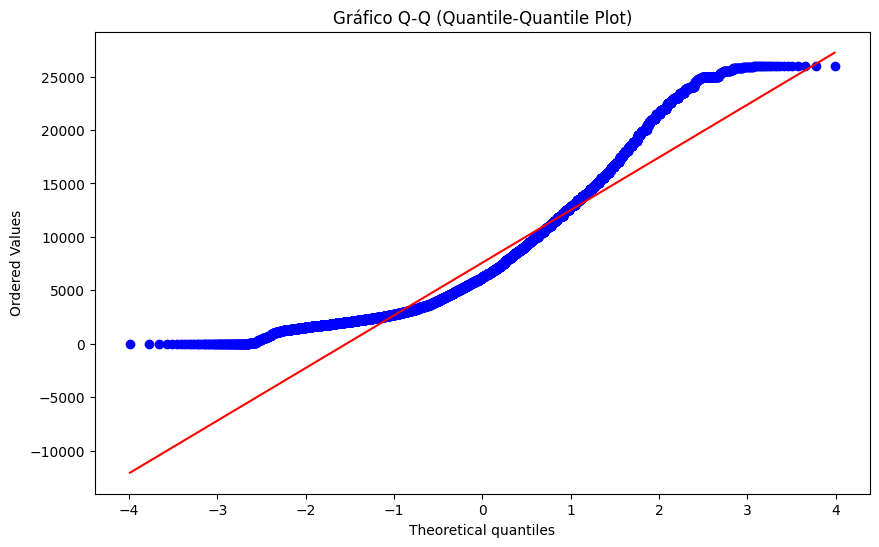

In [8]:
plt.figure(figsize=(10, 6))
stats.probplot(presio, dist="norm", plot=plt)
plt.title('Gráfico Q-Q (Quantile-Quantile Plot)')
plt.show()

Lo que nos muestra el gráfico anterior es que los datos no son normales ya que la curva presenta una curva cóncava que no se aproxima a una recta.

Referencia: 'Waples, J. (18 de Noviembre, 2024). *La Trama Q-Q: Qué significa y cómo interpretarlo*. Datacamp. Recuperado 27 de Marzo, 2026. De: https://www.datacamp.com/es/tutorial/qq-plot'

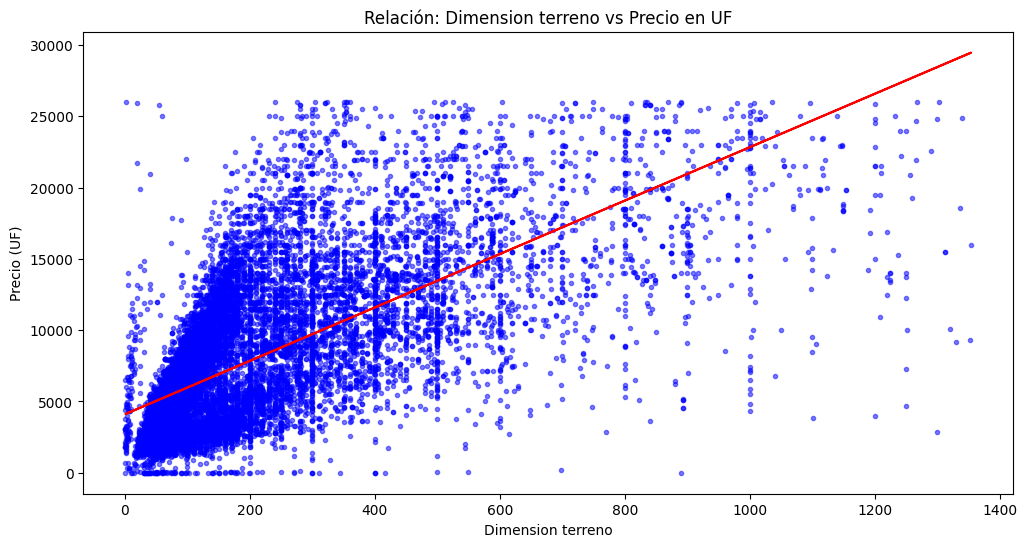

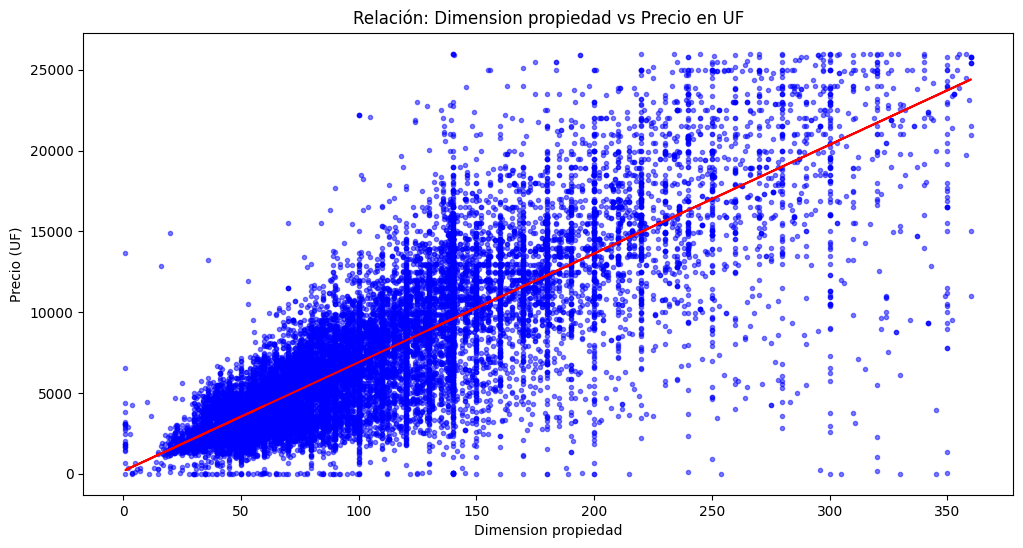

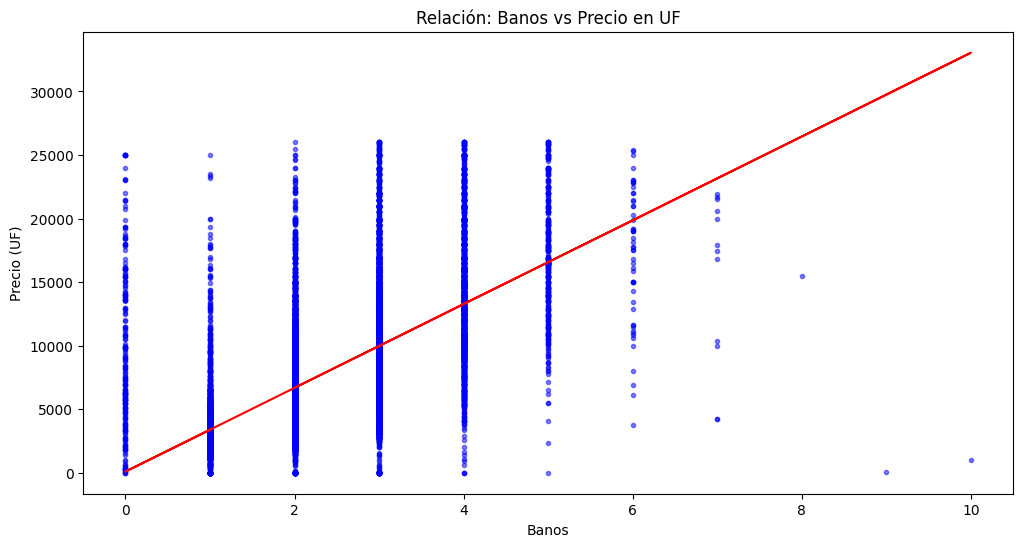

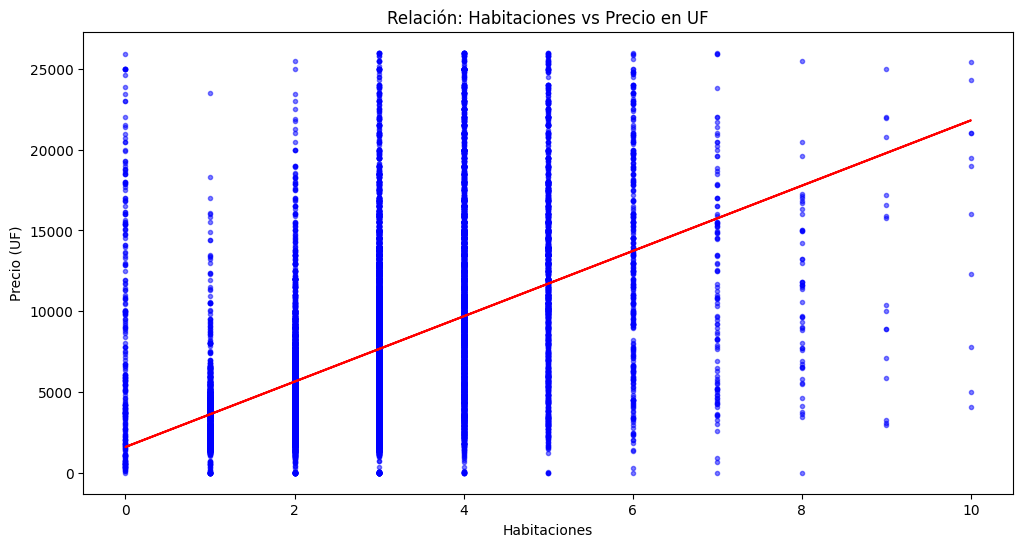

In [9]:
# Ahora veamos la relación entre variables relevantes y el precio:

var_rel = ['dimension_terreno','dimension_propiedad','banos','habitaciones']

for var in var_rel:
  # Esto lo hacemos para que si falta algun dato, esa fila no se utilice y así
  # tengan la misma cantidad
  temp_df = df[[var, 'precio_en_uf']].dropna()

  # Lo siguiente lo hacemos porque habían unos pocos datos muy separados del resto
  # por lo que para ver mejor la tendencia y relación entre variables decidí
  # quitarlos del gráfico, además dimensiones = 0 no hacen sentido.
  if var == 'dimension_terreno': temp_df = temp_df[temp_df[var] > 0]
  if var == 'dimension_propiedad': temp_df = temp_df[temp_df[var] > 0]
  if var == 'banos': temp_df = temp_df[temp_df[var] <= 10]
  if var == 'habitaciones': temp_df = temp_df[temp_df[var] <= 10]

  x = temp_df[var].values
  y = temp_df['precio_en_uf'].values
  fig, axs = plt.subplots(1, 1, figsize=(12, 6))

  axs.plot(x, y, marker='.', linestyle='none', color='blue', alpha=0.5)

  # Lo que hace la siguiente función (Por teorema de Weierstrass) es aproximar
  # la linea de tendencia a un polinomio de grado 1
  m, b = np.polyfit(x, y, 1)

  axs.plot(x, m*x + b, color='red')

  axs.set_title(f'Relación: {var.capitalize().replace("_", " ")} vs Precio en UF')
  axs.set_xlabel(f'{var.capitalize().replace("_", " ")}')
  axs.set_ylabel('Precio (UF)')

  plt.show()

In [10]:
# Podemos usar .corr() de pandas para ver la correlación
for var in var_rel:
  temp_df = df[[var, 'precio_en_uf']].dropna()
  print(f"Correlación entre {var.capitalize().replace('_', ' ')} y Precio en UF : {temp_df[f'{var}'].corr(temp_df['precio_en_uf'])}\n")


Correlación entre Dimension terreno y Precio en UF : 0.6381152461349933

Correlación entre Dimension propiedad y Precio en UF : 0.8212550478520114

Correlación entre Banos y Precio en UF : 0.6395451640228162

Correlación entre Habitaciones y Precio en UF : 0.46587982664998573



Primero, gráficamente se puede ver una mejor correlación o al menos alguna relación directa entre las dimensiones del terreno y la propiedad con el precio en UF, siendo estas dos features continuas, se puede obtener una ámplia gama de datos para poder entrenar a nuestro modelo. De las primeras dos figuras expuestas se puede concluir algo natural, que a medida que aumentan las dimensiones, aumenta el precio en UF de la propiedad. Así mismo estas variables presentan correlaciones positivas mayores que 0.5 por lo que respaldan esta hipótesis. Igualmente la característica que tiene una mayor correlación lineal con el precio es **Dimension propiedad con una correlación de 0.8213067687128939**, lo que indica que será una variable relevante a la hora de entrenar el modelo ya que se infiere que tiene una estrecha relación con la variación de los precios.

Por otro lado, las otras dos variables (baños y habitaciones) son discretas por lo que no se puede ver una tendencia muy clara. La línea de tendencia en rojo no puede aproximar este tipo de distribuciones por lo que tampoco entrega mucha información, igualmente me parece muy interesante que en casi todos los valores de nuestras variables, se obtiene un gran rango de valores de precio. Uno igual esperaría ver una tendencia (mientras más baños y habitaciones, más cara una propiedad), sin embargo en nuestro dataset no se observa eso, lo que también se refleja por ejemplo en el valor de la correlación entre **Habitaciones y precio, que es de 0.47589038814073753**. A pesar de ser positiva, no es un valor cercano a 1 por lo que no existe una gran correlación entre variables.

Estas últimas variables serían menos relevantes para el entrenamiento ya que no entregan mucha información generalizable, se puede ver gráficamente que una propiedad con 0 baños y/o 0 habitaciones puede costar mucho más que otra propiedad con 6+ ocurrencias de estas variables (y viceversa, también pueden costar 0 UF).



### 2.3.2 Procesamiento de datos

El pipeline de preprocesamiento parte primero eliminando la columna id ya que no va a ser relevante para nuestro modelo y así ahorramos en memoria. Luego se sigue analizando las filas en donde no hay un valor para el precio en UF o es 0. Dichas filas serán **eliminadas** ya que no aportan información para nuestro modelo de predicción, ya que no cuentan con nuestro dato a predecir o simplemente es absurdo que una propiedad teniendo un vector de características válido tenga un valor de 0 UF. Para buscar información sobre los métodos de procesamiento existentes se utilizó IA [2].

In [11]:
# 1 dropeamos los duplicados y la columna id ya que no nos entrega info
filtro = df.columns.drop('id')
df = df.drop_duplicates(subset=filtro)
df = df.drop(columns=['id'])

# 1.1: Trabajando en la tarea me di cuenta que hay columnas que son
# el string <null> por lo que las vamos a reemplazar para hacer los cálulos
df = df.replace('<null>', np.nan)

# 2
df = df.dropna(subset=['precio_en_uf'])
df = df[(df['precio_en_uf'] > 0)]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20502 entries, 0 to 20895
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_tipo_propiedad         20502 non-null  int64  
 1   descripcion               19506 non-null  object 
 2   habitaciones              20502 non-null  int64  
 3   banos                     20502 non-null  int64  
 4   dimension_propiedad       20502 non-null  float64
 5   dimension_terreno         20502 non-null  float64
 6   direccion                 20455 non-null  object 
 7   direccion_2               12896 non-null  object 
 8   id_comuna                 20502 non-null  int64  
 9   id_provincia              20388 non-null  object 
 10  id_region                 20502 non-null  int64  
 11  id_antiguedad             20502 non-null  int64  
 12  year                      16079 non-null  float64
 13  gastos_comunes            16234 non-null  float64
 14  piso       

Podemos apreciar que el numero de columnas sique siendo el mismo, por lo que cumplen con las condiciones especificadas. Igualmente con df.info() podemos ver el número de filas que presentan Nan values y su cuenta. Como se puede apreciar, todas las filas presentan un valor elevado de not Nan values, siendo la columna de **piso** la que menos datos presenta, sin embargo este valor no es lo suficientemente pequeño como para que estos valores sean eliminados de nuestro dataset.

Centrémonos en las variables de **piso** y **id_tipo_propiedad**:

In [12]:
print(f"Pisos: {df['piso'].value_counts()}")
print(f"\nTipos de propiedad: {df['id_tipo_propiedad'].value_counts()}")

Pisos: piso
2.0       1888
1.0        786
3.0        558
4.0        429
5.0        320
7.0        253
6.0        234
8.0        195
9.0        168
10.0       150
11.0       125
12.0       118
13.0       106
14.0        87
15.0        85
17.0        66
18.0        61
16.0        57
19.0        55
20.0        36
21.0        26
22.0        20
23.0        16
24.0        15
25.0        11
0.0         10
28.0         5
26.0         4
29.0         3
103.0        1
30.0         1
27.0         1
2006.0       1
32.0         1
37.0         1
Name: count, dtype: int64

Tipos de propiedad: id_tipo_propiedad
2    12577
1     7247
3      678
Name: count, dtype: int64


Notamos que en la feature de piso hay algunos valores extremos como que una propiedad está en el piso 2006 y algunos en el piso 0, se tendrá que analizar más a detalle el significado de esto. Ahora bien en los tipos de propiedad hay 3 valores, sin embargo en el enunciado salían que podían ser casa o departamento. Veamos algunos de estos datos:

In [13]:
df[df['id_tipo_propiedad'] == 1].head()

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,direccion,direccion_2,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
5,1,Cómoda casa de dos pisos pareada por ambos lad...,2,1,55.00,70.0,"Líbano, Macul, Región Metropolitana, Chile",NaN,292,43,13,2,NaN,0.0,2.0,1.0,f,24.0,2024.926477
9,1,"EN EXCLUSIVIDAD Casa de dos pisos, arquitectur...",3,3,273.00,826.0,Pedro de Valdivia / Monseñor Carlos Casanueva,Providencia ...,297,43,13,2,0.0,0.0,NaN,0.0,f,NaN,23000.000000
13,1,Casa dentro de condominio con seguridad 24 hor...,3,3,140.00,281.0,Hermosa casa en condominio tranquilo de Huechu...,Huechuraba ...,281,43,13,2,0.0,0.0,NaN,2.0,f,NaN,7700.000000
16,1,A PASOS DE BARRIO ITALIA - PARA REMODELAR COMP...,3,2,116.00,245.0,ABELARDO PIZARRO / CONDELL,Providencia ...,297,43,13,2,0.0,0.0,NaN,3.0,f,NaN,11390.930570
17,1,"Excelente propiedad en condominio, cercano a c...",3,3,93.95,164.0,"EN CONDOMINIO; COLEGIOS, COMERCIO",Huechuraba ...,281,43,13,2,0.0,50000.0,NaN,0.0,f,NaN,4550.000000


In [14]:
df[df['id_tipo_propiedad'] == 2].head()

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,direccion,direccion_2,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
0,2,"Estupendo departamento, Orientación Nor-orient...",3,2,130.0,140.0,AMERICO VESPUCIO FRANCISCO DE AGUIRRE,Vitacura ...,306,43,13,2,0.0,180000.0,NaN,2.0,f,NaN,11100.000000
2,2,DISPONIBLE!\nSe vende amplio y luminoso depart...,3,2,90.0,0.0,SECTOR METRO PRÍNCIPE DE GALES,La Reina ...,287,43,13,2,0.0,95000.0,NaN,1.0,f,1.0,5006.139010
3,2,Excelente departamento con inmejorable ubicaci...,2,3,65.0,0.0,Manuel Montt/Simón Bolivar,ÑUÑOA ...,294,43,13,2,0.0,0.0,NaN,1.0,f,NaN,4822.120381
4,2,Departamento muy bien ubicado y con buena vist...,3,2,140.0,200.0,Ex rotonda Perez Zujovic/Lateral Kennedy,Vitacura ...,306,43,13,2,0.0,275000.0,NaN,0.0,f,NaN,10490.000000
6,2,NaN,2,2,83.3,91.0,Camino Del Paisaje 6552,NaN,284,43,13,1,NaN,NaN,NaN,NaN,NaN,0.0,4800.000000


In [15]:
df[df['id_tipo_propiedad'] == 3].head()

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,direccion,direccion_2,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
1,3,"ID 27944 EXCELENTE PROPIEDAD COMERCIAL, corres...",7,3,207.0,350.0,LOS OLMOS,Macul ...,292,43,13,2,0.0,0.0,NaN,0.0,f,NaN,8300.000000
78,3,"29 m2 estupenda oficina, con espacios bien apr...",2,1,29.0,29.0,"AV. PEDRO DE VALDIVIA, A PASOS DEL METRO",Providencia ...,297,43,13,2,0.0,49000.0,NaN,0.0,f,NaN,2299.918188
81,3,SE VENDE OFICINA COMPLETAMENTE AMOBLADA O SIN ...,4,1,75.0,80.0,"Bandera 84, Santiago, Región Metropolitana, Chile",NaN,275,43,13,2,NaN,100000.0,2.0,0.0,t,5.0,4100.000000
90,3,Oficina ubicada en piso Nº 11 de edificio de 1...,7,3,157.0,157.0,Av Las Condes 9460,NaN,288,43,13,2,NaN,NaN,11.0,3.0,NaN,7.0,15986.073712
95,3,"Edificio inserto en Nueva Las Condes, cercano ...",2,1,21.0,21.0,"5620, Los Militares, Nueva Las Condes, Las Con...",NaN,288,43,13,2,5.0,45000.0,6.0,NaN,f,24.0,2300.000000


Por la descripción de estos tres dataframes podemos hacer el siguiente mapeo:


*   Casa -> 1
*   Departamento -> 2
*   Oficina/comercio -> 3

Vamos a analizar otros mapeos importantes, que es en las columnas de: **direccion**, **direccion_2**,**id_comuna** y con las columnas de **year** y **id_antiguedad**:

In [16]:
df[['direccion', 'direccion_2', 'id_comuna']]

,direccion,direccion_2,id_comuna
0,AMERICO VESPUCIO FRANCISCO DE AGUIRRE,Vitacura ...,306
1,LOS OLMOS,Macul ...,292
2,SECTOR METRO PRÍNCIPE DE GALES,La Reina ...,287
3,Manuel Montt/Simón Bolivar,ÑUÑOA ...,294
4,Ex rotonda Perez Zujovic/Lateral Kennedy,Vitacura ...,306
...,...,...,...
20891,Av. Grecia/ Pedro Alessandri,NaN,294
20892,PADRE HURTADO/ MARDOÑAL,Las Condes ...,288
20893,Alto El Manzano - Condominio Alto El Manzano,Til Til ...,312
20894,BILBAO/ MANQUEHUE,Las Condes ...,288


In [17]:
print(df['direccion_2'].str.upper().value_counts())
print(f"\n{df['id_comuna'].value_counts()}")

direccion_2
LAS CONDES                                                                                                                                                                                                                                                         2874
SANTIAGO                                                                                                                                                                                                                                                           1520
ÑUÑOA                                                                                                                                                                                                                                                              1344
VITACURA                                                                                                                                                                                            

No sabía como usar upper en pandas, la referencia del código es de:
Vikas. (14 de diciembre de 2021). How to make particular column values as upper case [Comentario en un foro en línea]. Stack Overflow. https://stackoverflow.com/questions/70375093/how-to-make-particular-column-values-as-upper-case

In [18]:
# Veamos que ocurre con los id comuna = 0
df[(df['id_comuna'] == 0) & (df['direccion_2'].notna())].head()

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,direccion,direccion_2,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
2257,1,Disponible!!!\n\n* Casa sector villa las camel...,2,1,42.0,78.0,"COD: BC SECTOR VILLAS LAS CAMELIAS, EL MONTE",El Monte ...,0,43,13,2,0.0,0.0,NaN,0.0,f,1.0,1303.148552
11332,1,"Casa en Alto El Manzano , ubicado en kilometro...",4,4,164.0,340.0,ALTO EL MANZANO,Til Til ...,0,43,13,2,0.0,10000.0,NaN,2.0,f,NaN,4350.000019
11620,1,"PRIMER PISO\nLiving comedor separados, dormito...",3,3,174.0,350.0,JARDIN ORIENTE,Tiltil ...,0,43,13,2,0.0,35000.0,NaN,2.0,f,1.0,5000.000000
13024,1,Disponible!!!\n\n* Casa sector villa las camel...,2,1,42.0,78.0,"COD: BC SECTOR VILLAS LAS CAMELIAS, EL MONTE",El Monte ...,0,43,13,2,0.0,0.0,NaN,0.0,f,NaN,1297.086959
13493,1,"Casa en Condominio de sólo 5 casas, ubicado en...",3,2,110.0,280.0,"SÓLIDA Y CENTRAL CASA EN EL MONTE, SANTIAGO",El Monte ...,0,43,13,2,0.0,0.0,NaN,1.0,f,NaN,3464.308184


Estos códigos nos muestran que hay filas sin un id de comuna asociado y que las filas que tienen dirección 2 == Til til o El Monte se le asigna el valor 0, intentaremos mapear estas últimas al valor correcto de su comuna, sino les daremos uno propio (reemplazando el 0 por un id que no se esté utilizando), esto es por que considero que dirección y dirección 2 pueden ser resumidas por la columna id_comuna de manera bastante buena, simplificando el modelo y facilitando el entrenamiento ya que se mapea un dato que es categórico (string) a un identificador único.

In [19]:
# Para esto limpiemos la columna direccion_2, añadimos una columna temporal:
df['dir2'] = df['direccion_2'].str.upper().str.strip()

# Trabajamos con un dataframe temporal:
df_validos = df[(df['id_comuna'] != 0) &
                (df['id_comuna'].notna()) &
                (df['dir2'].notna())]

# Uso de IA [3]
comunas = df_validos.groupby('id_comuna')['dir2'].apply(lambda x: x.mode()[0]).reset_index()

# Hacemos el mapa
mapeo_comunas = dict(zip(comunas['dir2'], comunas['id_comuna']))
print(mapeo_comunas)


{'SANTIAGO': 275, 'CERRILLOS': 276, 'CERRO NAVIA': 277, 'CONCHALÍ': 278, 'EL BOSQUE': 279, 'ESTACIÓN CENTRAL': 280, 'HUECHURABA': 281, 'INDEPENDENCIA': 282, 'LA CISTERNA': 283, 'LA FLORIDA': 284, 'LA GRANJA': 285, 'LA PINTANA': 286, 'LA REINA': 287, 'LAS CONDES': 288, 'LO BARNECHEA': 289, 'LO ESPEJO': 290, 'LO PRADO': 291, 'MACUL': 292, 'MAIPÚ': 293, 'ÑUÑOA': 294, 'PEDRO AGUIRRE CERDA': 295, 'PEÑALOLÉN': 296, 'PROVIDENCIA': 297, 'PUDAHUEL': 298, 'QUILICURA': 299, 'QUINTA NORMAL': 300, 'RECOLETA': 301, 'RENCA': 302, 'SAN JOAQUÍN': 303, 'SAN MIGUEL': 304, 'SAN RAMÓN': 305, 'VITACURA': 306, 'PUENTE ALTO': 307, 'PIRQUE': 308, 'SAN JOSÉ DE MAIPO': 309, 'COLINA': 310, 'LAMPA': 311, 'TIL TIL': 312, 'SAN BERNARDO': 313, 'BUIN': 314, 'CALERA DE TANGO': 315, 'PAINE': 316, 'MELIPILLA': 317, 'CURACAVI': 319, 'MARÍA PINTO': 320, 'SAN PEDRO': 321, 'TALAGANTE': 322, 'EL MONTE': 323, 'ISLA DE MAIPO': 324, 'PADRE HURTADO': 325, 'PEÑAFLOR': 326}


In [20]:
# Vemos que Til Til y El monte tienen id de comuna, ataquemos estas filas:
filas_malas = (df['id_comuna'] == 0) | (df['id_comuna'].isna())


# Escribiendo la linea en colab, me la autocompletó
# Lo que hace es reescribir en nuestro df buscando en las filas malas el id (0)
# Mira lo que está en dir2 y mapea este texto a los valores de nuestro diccionario con map
# Si no encuentra nada devuelve NaN, pero usamos fillna para que devuelva el valor original (0)
df.loc[filas_malas, 'id_comuna'] = df.loc[filas_malas, 'dir2'].map(mapeo_comunas).fillna(df.loc[filas_malas, 'id_comuna'])

df[(df['id_comuna'] == 0) & (df['direccion_2'].notna())]


,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,direccion,direccion_2,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf,dir2
11620,1,"PRIMER PISO\nLiving comedor separados, dormito...",3,3,174.0,350.0,JARDIN ORIENTE,Tiltil ...,0,43,13,2,0.0,35000.0,NaN,2.0,f,1.0,5000.0,TILTIL


No sabía como filtrar con er "or" en pandas, lo obtive de:
Pshir. (13 de septiembre de 2021). Filtering pandas dataframe using 'OR' statement [Comentario en un foro en línea]. Stack Overflow. https://stackoverflow.com/questions/29461185/filtering-pandas-dataframe-using-or-statement

In [21]:
# Notamos que solo nos queda 1 fila que es porque TILTIL está sin espacio
# Resolvemos manualmente
df.at[11620,'id_comuna'] = mapeo_comunas['TIL TIL']
df.iloc[11620]

id_tipo_propiedad                                                           2
descripcion                 Amplio departamento de 4 dormitorios, 2 baños ...
habitaciones                                                                4
banos                                                                       3
dimension_propiedad                                                      95.0
dimension_terreno                                                       116.0
direccion                                                    CHILE ESPAÑA 720
direccion_2                                                               NaN
id_comuna                                                                 294
id_provincia                                                               43
id_region                                                                  13
id_antiguedad                                                               2
year                                                            

El at lo saqué de la documentación de pandas:
Pandas. (s.f.). pandas.DataFrame.at. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.at.html#pandas.DataFrame.at

In [22]:
# Tenemos todas nuestras filas ordenadas y tenemos el mapeo de comunas
# Es por esto que eliminaré las columnas temporales, la de direccion_2 y direccion
# Borro la variable direccion ya que sería complicado preprocesar las calles y sectores
# Al final tiene mucho más peso la comuna que la calle específica
df = df.drop(columns=['direccion_2','dir2', 'direccion'])

In [23]:
# Hacemos el mismo proceso anterior para year y id_antiguedad
df['year'] = df['year'].fillna(0)
df
print(df['year'].value_counts())
print(f"\n{df['id_antiguedad'].value_counts()}")

year
0.0       15854
2015.0      266
2014.0      247
2016.0      232
2017.0      225
          ...  
7.0           1
1934.0        1
1912.0        1
54.0          1
988.0         1
Name: count, Length: 140, dtype: int64

id_antiguedad
2    19142
1     1360
Name: count, dtype: int64


In [24]:
# Notamos valores anómalos y tambien muchos 0 en la columna year
# Ahora veamos que significan los id de antiguedad
df[df['id_antiguedad'] == 1].head()

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
6,2,NaN,2,2,83.30,91.00,284,43,13,1,0.0,NaN,NaN,NaN,NaN,0.0,4800.000000
7,2,Departamento Nuevo80 mts2Piso 9 (último piso)2...,2,2,80.00,80.00,288,43,13,1,0.0,75000.0,NaN,1.0,f,NaN,6750.000000
10,2,"Santiago Centro, departamento casi nuevo, San...",2,2,54.00,54.00,275,43,13,1,0.0,77000.0,20.0,1.0,f,11.0,3657.017139
14,2,NaN,2,2,80.69,94.38,297,43,13,1,0.0,NaN,4.0,NaN,NaN,0.0,8373.000000
57,2,NaN,2,2,65.19,65.19,304,43,13,1,0.0,NaN,11.0,NaN,NaN,0.0,3195.000000


In [25]:
df[df['id_antiguedad'] == 2].head()

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
0,2,"Estupendo departamento, Orientación Nor-orient...",3,2,130.0,140.0,306,43,13,2,0.0,180000.0,NaN,2.0,f,NaN,11100.000000
1,3,"ID 27944 EXCELENTE PROPIEDAD COMERCIAL, corres...",7,3,207.0,350.0,292,43,13,2,0.0,0.0,NaN,0.0,f,NaN,8300.000000
2,2,DISPONIBLE!\nSe vende amplio y luminoso depart...,3,2,90.0,0.0,287,43,13,2,0.0,95000.0,NaN,1.0,f,1.0,5006.139010
3,2,Excelente departamento con inmejorable ubicaci...,2,3,65.0,0.0,294,43,13,2,0.0,0.0,NaN,1.0,f,NaN,4822.120381
4,2,Departamento muy bien ubicado y con buena vist...,3,2,140.0,200.0,306,43,13,2,0.0,275000.0,NaN,0.0,f,NaN,10490.000000


In [26]:
# Comprobamos una cosa
df[df['descripcion'].str.upper().str.contains('NUEVO|NUEVA', na=False)]

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_region,id_antiguedad,year,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
7,2,Departamento Nuevo80 mts2Piso 9 (último piso)2...,2,2,80.0,80.0,288,43,13,1,0.0,75000.0,NaN,1.0,f,NaN,6750.000000
10,2,"Santiago Centro, departamento casi nuevo, San...",2,2,54.0,54.0,275,43,13,1,0.0,77000.0,20.0,1.0,f,11.0,3657.017139
19,2,EXCELENTE DEPARTAMENTO de orientación Norte y ...,4,5,200.0,234.0,306,43,13,2,0.0,400000.0,NaN,3.0,f,NaN,18500.000000
20,2,Gran departamento como nuevo en Condominio Bos...,3,3,118.0,154.0,281,43,13,2,0.0,0.0,NaN,2.0,f,NaN,8290.000000
24,2,"Lindo departamento hall, living comedor de bue...",3,4,120.0,120.0,289,43,13,2,0.0,NaN,3.0,2.0,f,17.0,11000.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20830,1,MIRA LA CIUDAD DESDE LO ALTO!!!\r\nMaravillosa...,5,5,263.0,685.0,287,43,13,1,2017.0,NaN,2.0,3.0,f,24.0,19400.000000
20836,2,"Excelente oportunidad de inversión, departamen...",3,2,58.0,58.0,282,43,13,2,0.0,50000.0,NaN,0.0,f,NaN,2827.257771
20841,2,Espectacular departamento duplex nuevo en un b...,4,4,138.3,201.7,288,43,13,1,2018.0,NaN,1.0,2.0,f,15.0,13490.000000
20853,2,OPORTUNIDAD A pocas cuadras de Metro Santa Luc...,2,1,40.0,40.0,275,43,13,2,0.0,50000.0,NaN,1.0,f,NaN,2789.999985


In [27]:
# id_antiguedad 1
print(df.at[20830, 'descripcion'])
print('-------------------------')
print(df.at[20841, 'descripcion'])
print('-------------------------')
# id_antiguedad 2
print(df.at[19, 'descripcion'])
print('-------------------------')
print(df.at[24, 'descripcion'])

MIRA LA CIUDAD DESDE LO ALTO!!!
Maravillosa propiedad ubicada en La Reina Alta, casa nueva de 263 mt2 Construidos en 685 mt2 de terreno, con 5 Dormitorios y 5 Baños de 2 pisos. Es una construcción  sólida,  con amplios y comodos espacios  muy bien pensados y diseñados  con   terminaciones de alto nivel.
Casa muy iluminada con grandes ventanales de PVC con termopaneles desde donde se contempla la cuidad desde lo alto de la Reina en Alvaro Casanova, una hermosa comuna donde se fusiona la precordillera con la cuidad en un condominio cerrado de tres propiedades y cerca de completos centros comerciales, colegios y aire puro.
Su cocina está muy bien distribuida cuenta con una isla con cocina encimera, horno eléctrico  y horno microondas empotrados  con amplios y funcionales muebles. 
 Living y comedor por separados con  grandes ventanales que miran al patio. Espaciosa Suite matrimonial el baño cuenta con dos lavamanos y un  gran vestidor muy iluminado adicionalmente un cuarto que perfectamen

Las descripciones de las propiedades nos hacen darnos cuenta del mapeo de **id_antiguedad**:

* Propiedad nueva -> 1
* Propiedad usada -> 2

Tambien por la cantidad de 0 en la columna de **year** es que decidí eliminarla, no se me ocurre la forma de encontrar el valor del año en que la propiedad fue construida más que por inspección manual de cada descripción, luego, esta columna no aporta nada al modelo predictivo. Por el contrario a **id_antiguedad** que es muy relevante.

In [28]:
df = df.drop(columns=['year'])

In [29]:
# Algunos otros análisis
print(df['id_region'].value_counts())
print(f"\n{df['amoblado'].value_counts()}")
print(f"\nNaN en amoblado: {df['amoblado'].isna().sum()}")

id_region
13    20502
Name: count, dtype: int64

amoblado
f    17793
t      426
Name: count, dtype: int64

NaN en amoblado: 2283


También podemos eliminar la columna de **id_region** ya que todas las propiedades se encuentran en la región metropolitana (id 13) por lo que esta columna no entrega información. Con la columna de **id_provincia** hacemos un mapeo con los id de la comuna -> id provincia para transformar los NaN. Por otro lado tenemos que en la columna de **amoblado** nos dicen si las propiedades están amobladas con un true o false (f o t), también hay 2300 propiedades las cuales no se nos entrega información.

In [30]:
df = df.drop(columns=['id_region'])

In [31]:
mapa_comuna_provincia = df.dropna(subset=['id_provincia']).groupby('id_comuna')['id_provincia'].first()

df['id_provincia'] = df['id_provincia'].fillna(df['id_comuna'].map(mapa_comuna_provincia))
# Quedan 51 datos que aún no tienen id_provincia, los dropeamos (0.2% de la muestra)
df = df.dropna(subset=['id_provincia'])

In [32]:
# df[df['amoblado'].isna()] -> Así vemos los indices
print(df.at[72, 'descripcion'])
print('-------------------------')
print(df.at[20847, 'descripcion'])
print('-------------------------')
print(df.at[20872, 'descripcion'])
print('-------------------------')
print(df.at[20883, 'descripcion'])

UF 10.900  VITACURA ESQUINA  DE BALAGUER
Precioso departamento buena ubicación 3 dormitorios 3 baños Amplia Cocina Pieza de Servicio 2 terrazas 2 estacionamientos bodega Piscina Gimnasio 140 MTS 2 Cerca de Supermercados, Colegios, Malls,a pasos de todo, lado Autopista Costanera Norte
-------------------------
Se vende oficina remodelada de 115 mt2 útiles con 3 privados y 3 baños, ubicado en Catedral 1233 entre Morandé con Teatinos, Santiago Centro, a pasos del metro Santa Ana y Plaza de Armas, Tribunales, CBR, la oficina se encuentra recién alfombrada, tiene recepción con baño independiente, algunos privados cuentan con fino revestimiento en madera, además, el privado principal cuenta con una biblioteca de 2,55 mt de alto x 4,26 mt de largo, la ubicación y orientación Norte - Sur que tiene la oficina, permite una atmósfera agradable , y el ruido es casi nulo. Ideal abogados, arquitectos, receptores.

El edificio cuenta con 3 ascensores y seguridad 24/7.

Gastos comunes: $70.000 app.

-

Aunque podemos ver que en algunas filas con la descripción sabemos si está amoblada una propiedad y podemos hacer un código o manualmente introducir estos datos, yo voy a **eliminar** las filas que no entregan información sobre si están amobladas o no. Esta decisión la hago teniendo en cuenta que estas filas representan una fracción pequeña de los datos (11%) y al no tener una manera segura de poder reeplazar los valores NaN decido quitarlas del modelo.

A su vez, también hacemos el mapeo de valores booleanos a ints para que sean entendidos por el modelo:

* f -> 0
* t -> 1

In [33]:
df = df.dropna(subset='amoblado')
mapeo_muebles = {'f': 0, 't': 1}
df['amoblado'] = df['amoblado'].replace(mapeo_muebles)

C:\Users\Rafal\AppData\Local\Temp\ipykernel_42796\976335440.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['amoblado'] = df['amoblado'].replace(mapeo_muebles)


Sigamos con las variables: **cantidad_caracteristicas**, **piso** y **gastos_comunes**.

In [34]:
#df['cantidad_caracteristicas'].value_counts()
print(f"NaN en c_c: {df['cantidad_caracteristicas'].isna().sum()}")
df[df['cantidad_caracteristicas'] == 0].head()

NaN en c_c: 11267


,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_antiguedad,gastos_comunes,piso,estacionamientos,amoblado,cantidad_caracteristicas,precio_en_uf
50,2,Excelente y Hermosos Departamento en Avenida I...,3,2,81.0,91.0,294,43,2,NaN,NaN,2.0,0,0.0,5589.339605
61,2,"EXCELENTE OPORTUNIDAD. Hall de entrada, living...",2,2,70.0,75.0,288,43,2,0.0,NaN,1.0,0,0.0,5490.000000
82,1,Propiedad ubicada por Avenida Gabriela ponient...,5,2,52.0,115.0,307,44,2,0.0,NaN,0.0,0,0.0,2163.065583
92,2,"Departamento con muy buena ubicación, entre me...",2,2,51.0,52.0,275,43,2,65000.0,16.0,NaN,0,0.0,2120.490749
114,2,Amplio departamento emplazado en el corazón de...,3,2,88.0,90.0,297,43,2,0.0,NaN,0.0,0,0.0,6170.000000


No puedo encontrarle un significado a esta variable, creo que es error humano o flojera la cantidad de NaN values y además de que por la descripción de las propiedades es que no creo que encuentre una manera confiable para asignarle un número a dicha feature, por lo que dropeamos la columna.

Sigamos con la variable **piso**.

In [35]:
# Dropeamos y seguimos
df.drop(columns=['cantidad_caracteristicas'], inplace=True)

print(f"NaN en piso: {df['piso'].isna().sum()}")
df.groupby('id_tipo_propiedad')['piso'].value_counts(dropna=False)

NaN en piso: 13817


id_tipo_propiedad  piso  
1                  NaN       4816
                   2.0       1129
                   1.0        441
                   3.0        121
                   0.0          3
                   4.0          3
                   10.0         2
                   20.0         1
                   22.0         1
2                  NaN       8457
                   2.0        309
                   4.0        287
                   3.0        279
                   5.0        204
                   7.0        171
                   1.0        157
                   6.0        150
                   8.0        134
                   9.0        124
                   10.0       101
                   12.0        80
                   11.0        77
                   13.0        70
                   15.0        60
                   14.0        59
                   18.0        47
                   17.0        46
                   19.0        45
                   16.

In [36]:
# Voy a comentar los siguientes pero los revisé todos

# Casas
#df[(df['piso'] == 0) & (df['id_tipo_propiedad'] == 1)].head() 2 casas de 1 piso y #11750 es un terreno
#df[(df['piso'] == 1) & (df['id_tipo_propiedad'] == 1)].head() casas de 1 piso
#df[(df['piso'] == 2) & (df['id_tipo_propiedad'] == 1)].head() casas de 2 pisos
#df[(df['piso'] == 3) & (df['id_tipo_propiedad'] == 1)].head() casas de 3 pisos
df[(df['piso'] == 4) & (df['id_tipo_propiedad'] == 1)] # 3 propiedades donde hay 1 casa (3 pisos) y 2 propiedades mal inputadas

# Departamentos
#df[(df['piso'] == 0) & (df['id_tipo_propiedad'] == 2)].head() #Mal inputados, no se dice el piso
#df[(df['piso'] == 1) & (df['id_tipo_propiedad'] == 2)].head()
#df[(df['piso'] == 26) & (df['id_tipo_propiedad'] == 2)].head()
df[(df['piso'] == 2006) & (df['id_tipo_propiedad'] == 2)].head() #Mal inputado
df.at[8080, 'piso'] = 0 # Por mientras lo cambiamos

# Comercios
#df[(df['piso'] == 1) & (df['id_tipo_propiedad'] == 3)].head() Puras oficinas bien inputadas
df[(df['piso'] == 2) & (df['id_tipo_propiedad'] == 3)].head()
df[(df['piso'] == 11) & (df['id_tipo_propiedad'] == 3)].head()
df[(df['piso'].isna()) & (df['id_tipo_propiedad'] == 3)].head()

print(df.at[78, 'descripcion']) #-> usaba esto para ver la descripción

29 m2 estupenda oficina, con espacios bien aprovechados, recepción, sala de reuniones, 2 privados. Equipado con muebles ( escritorios), closet, baño remodelado, aire acondicionado. A pasos del metro. Edificio seguro con circuito cerrado. Funciona 24/7
sin estacionamiento, sin bodega, gastos comunes $ 45.000, contribuciones  $ 87.000
arriendo con compromiso de venta. Valor de arriendo $ 350.000  hasta mayo 2019, 


Agrupamos por el tipo de propiedad, podemos ver que la variable sirve para cosas distintas. Cuando la propiedad es una casa, la variable piso significa cuantos pisos tiene la casa. Igualmente hay unos valores muy anómalos por lo que vamos a cambiar los valores de las casas que dicen tener 4 o más pisos (se revisó y la casa que estaba en el nivel 4, al final tenía tres plantas).

Por otro lado, si la propiedad era departamento o una propiedad comercial, el piso sí indica en qué piso está ubicada la propiedad.

Igualmente se creará una nueva columna solo para las casas en donde se señala el número de pisos que tienen (los departamentos y oficinas valen 0 en sus casillas), por su parte luego de eliminar las filas de departamentos con piso = 0 (se puede hacer ya que eliminaría 7 filas, que son muy pocos datos), se cambia este valor para todas las casas a 0 ya que están a nivel de la calle.

Finalmente los NaN en los datasets en general suelen reemplazarse con la media, la mediana o la moda. Decidí optar por la mediana debido a las siguientes razones:

1. Es deseable inputar la mediana cuando se presenta asimetría.

2. Es deseable inputar la mediana con la presencia de outliers ya que es afectada en menor medida por los valores extremos.

APXML. (s.f.). Basic imputation: Mean, median, mode. Intro to Data Cleaning & Preprocessing. https://apxml.com/courses/intro-data-cleaning-preprocessing/chapter-2-handling-missing-data/basic-imputation-mean-median-mode

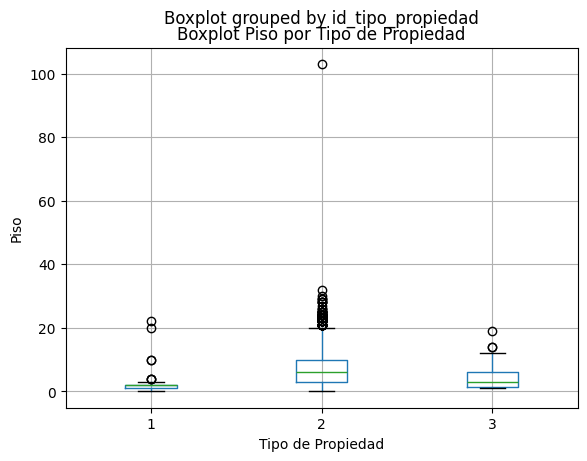

In [37]:
# Hacemos un boxplot para ver simetría
df.boxplot(column='piso', by='id_tipo_propiedad')
plt.title('Boxplot Piso por Tipo de Propiedad')
plt.xlabel('Tipo de Propiedad')
plt.ylabel('Piso')
plt.show()

Se nota fuertemente la presencia de outliers y de que nuestros datos presentan asimetría.

Pandas. (s.f.). pandas.DataFrame.boxplot. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.boxplot.html

Luego nuestros NaN los cambiamos por la mediana de los datos, es importante calcular la mediana de los datos del dataset de entrenamiento para intentar no inducir data leakage (Se hará en la siguiente sección).

In [38]:
# Hacemos los cambios propuestos

# Primero cambiamos las casas con más de 4 pisos a departamentos:
df.loc[df['piso'] > 4, 'id_tipo_propiedad'] = 2
df.at[7358, 'piso'] = 3 # Esta casa tenía 3 pisos
df.at[11010, 'id_tipo_propiedad'] = 2 # Esta era depto
df.drop(10314, inplace=True) # Mal input y es 1 solo dato

# Creamos una columna para mostrar el número de plantas (casas)
df['numero_de_plantas'] = np.where(df['id_tipo_propiedad'] == 1, df['piso'], 0)
# Cambiamos los valores del piso en las casas a 0
df.loc[df['id_tipo_propiedad'] == 1, 'piso'] = 0

# Dropeamos las filas de deptos en piso 0
df = df.drop(df[(df['id_tipo_propiedad'] == 2) & (df['piso'] == 0)].index)
df

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_antiguedad,gastos_comunes,piso,estacionamientos,amoblado,precio_en_uf,numero_de_plantas
0,2,"Estupendo departamento, Orientación Nor-orient...",3,2,130.0,140.0,306,43,2,180000.0,NaN,2.0,0,11100.000000,0.0
1,3,"ID 27944 EXCELENTE PROPIEDAD COMERCIAL, corres...",7,3,207.0,350.0,292,43,2,0.0,NaN,0.0,0,8300.000000,0.0
2,2,DISPONIBLE!\nSe vende amplio y luminoso depart...,3,2,90.0,0.0,287,43,2,95000.0,NaN,1.0,0,5006.139010,0.0
3,2,Excelente departamento con inmejorable ubicaci...,2,3,65.0,0.0,294,43,2,0.0,NaN,1.0,0,4822.120381,0.0
4,2,Departamento muy bien ubicado y con buena vist...,3,2,140.0,200.0,306,43,2,275000.0,NaN,0.0,0,10490.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20891,2,Hermoso Departamento. Edificio Full Equipado (...,3,2,71.0,75.0,294,43,2,3.0,5.0,1.0,0,4600.000000,0.0
20892,2,PADRE HURTADO CENTRAL / MARDOÑAL \n\nDepartame...,2,1,60.0,60.0,288,43,2,40000.0,NaN,0.0,0,4289.500298,0.0
20893,1,"Condominio Alto El Manzano, Km 35 de Panameric...",3,3,86.0,224.0,312,45,2,0.0,0.0,0.0,0,2793.320409,NaN
20894,2,"Excelente 158 mts. incluida terraza, a pasos d...",3,0,158.0,158.0,288,43,2,250000.0,NaN,0.0,0,12500.000000,0.0


Finalmente podemos ver que ocurre con la característica **gastos_comunes**:

In [39]:
print(f"NaN en gastos comunes: {df['gastos_comunes'].isna().sum()}")
print(df.groupby('id_tipo_propiedad')['gastos_comunes'].value_counts(dropna=False))

NaN en gastos comunes: 2311
id_tipo_propiedad  gastos_comunes
1                  0.0               4261
                   NaN               1378
                   100000.0            41
                   50000.0             38
                   70000.0             34
                                     ... 
3                  550000.0             1
                   670000.0             1
                   1080000.0            1
                   1300000.0            1
                   650000000.0          1
Name: count, Length: 644, dtype: int64


In [40]:
# Casas
df[(df['gastos_comunes'].isna()) & (df['id_tipo_propiedad'] == 1)].head()
df[(df['gastos_comunes'] == 0) & (df['id_tipo_propiedad'] == 1)]
df[(df['gastos_comunes'] > 1) & (df['id_tipo_propiedad'] == 1)] # Casas en condominio
# Veamos los datos anómalos
df[(df['gastos_comunes'] > 1000000) & (df['id_tipo_propiedad'] == 1)]
df.loc[df['gastos_comunes'] == 130000312, 'gastos_comunes'] = 130000 # En la descripción
df.loc[df['gastos_comunes'] == 380000000, 'gastos_comunes'] = 0 # No lo encontré
# Asumimos que los NaN son casas sin gastos comunes
df.loc[df['gastos_comunes'].isna(), 'gastos_comunes'] = 0

# Departamentos
df[(df['gastos_comunes'] == 0) & (df['id_tipo_propiedad'] == 2)] # 4872 datos
df[(df['gastos_comunes'].isna()) & (df['id_tipo_propiedad'] == 2)] # 909 datos
#df[(df['gastos_comunes'] > 1) & (df['id_tipo_propiedad'] == 2)] # 5524 datos
# Datos anómalos
df[(df['gastos_comunes'] > 1000000) & (df['id_tipo_propiedad'] == 2)]
# Voy a cambiarlos a NaN los que no puedo extraer los datos de ninguna parte
df.loc[df['gastos_comunes'] == 1100000, 'gastos_comunes'] = 110000
df.loc[(df['gastos_comunes'] > 1000000) & (df['id_tipo_propiedad'] == 2) , 'gastos_comunes'] = pd.NA

# Propiedades comerciales
#df[(df['gastos_comunes'].isnull()) & (df['id_tipo_propiedad'] == 3)] # 43 datos
#df[(df['gastos_comunes'] == 0) & (df['id_tipo_propiedad'] == 3)] # 418 datos
#df[(df['gastos_comunes'] > 1) & (df['id_tipo_propiedad'] == 3)] # 149 datos
# Hay un valor muy anómalo aca, lo vamos a analizar
#df.loc[df['gastos_comunes'] == 650000000] # Estaba mal inputado $650.000
df.loc[df['gastos_comunes'] == 650000000, 'gastos_comunes'] = 650000

#print(df.at[879, 'descripcion']) #-> usaba esto para ver la descripción


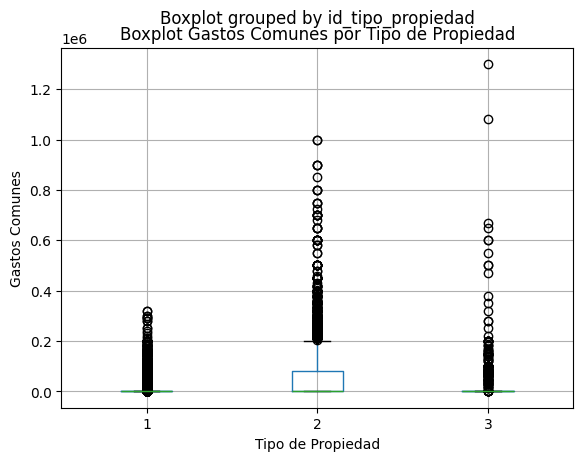

In [41]:
# Nuevamente hacemos un boxplot para ver simetría
df.boxplot(column='gastos_comunes', by='id_tipo_propiedad')
plt.title('Boxplot Gastos Comunes por Tipo de Propiedad')
plt.xlabel('Tipo de Propiedad')
plt.ylabel('Gastos Comunes')
plt.show()

Aún trabajando en los outliers podemos ver con el boxplot la inmensa asimetría de estos datos, es por eso que imputaremos nuevamente la media en los datos faltantes de la variable **gastos_comunes**, eso sí, creo que sería bueno también aplicarle un filtro, como por ejemplo tomar la media de los departamentos por *comuna* o algún otro indicador para que sea más fiel dicho valor.

In [42]:
# Se me pasó limpiar los estacionamientos, igual los NaN, les ponemos 0
df['estacionamientos'] = df['estacionamientos'].fillna(0)
df.loc[df['estacionamientos'] > 19]
#print(df.at[16232, 'descripcion']) #6743 -> 1

# En general para las casas y deptos que tengan más de 10 estacionamientos es un error
df.loc[6743 , 'estacionamientos'] = 1 # Esta leimos su descripcion de suerte
# Lo que hacemos es filtrar las casas y deptos (id 1 o 2) para que tengan
# <= 10 estacionamientos, ya que es posible que una propiedad comercial tenga más
df = df[(df['id_tipo_propiedad'] == 3) | (df['estacionamientos'] <= 10)]

In [43]:
df['estacionamientos'].value_counts()

estacionamientos
0.0     7358
1.0     5824
2.0     3477
3.0      899
4.0      345
5.0      104
6.0       64
10.0      21
8.0       12
7.0        9
9.0        3
15.0       1
Name: count, dtype: int64

Solo queda por filtrar las variables que utilizamos en la sección **2.3.1**. Aplicando los mismos criterios:

In [44]:
# USO DE IA [5]
df = df.copy()

# Primero si la dimensión de la propiedad es NaN, hacerla = 0
df['dimension_propiedad'] = df['dimension_propiedad'].fillna(0)

# Segundo si dim terreno es NaN, ponerle igual a la de propiedad
df['dimension_terreno'] = df['dimension_terreno'].fillna(df['dimension_propiedad'])

# Ahora, la superficie construida no puede ser mayor que la del terreno
filter = df['dimension_propiedad'] > df['dimension_terreno']
df.loc[filter, 'dimension_propiedad'] = df.loc[filter, 'dimension_terreno']

# Filtramos los negativos
df = df[(df['dimension_terreno'] >= 0) & (df['dimension_propiedad'] >= 0)]

# Lo mismo para los baños, habitaciones y estacionamientos
df = df[(df['banos'] >= 0) & (df['habitaciones'] >= 0) & (df['estacionamientos'] >= 0)]

# Finalmente filtramos por los mismos criterios de 2.3.1
df = df[(df['banos'] <= 10) & (df['habitaciones'] <= 10)]

df

,id_tipo_propiedad,descripcion,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_antiguedad,gastos_comunes,piso,estacionamientos,amoblado,precio_en_uf,numero_de_plantas
0,2,"Estupendo departamento, Orientación Nor-orient...",3,2,130.0,140.0,306,43,2,180000.0,NaN,2.0,0,11100.000000,0.0
1,3,"ID 27944 EXCELENTE PROPIEDAD COMERCIAL, corres...",7,3,207.0,350.0,292,43,2,0.0,NaN,0.0,0,8300.000000,0.0
2,2,DISPONIBLE!\nSe vende amplio y luminoso depart...,3,2,0.0,0.0,287,43,2,95000.0,NaN,1.0,0,5006.139010,0.0
3,2,Excelente departamento con inmejorable ubicaci...,2,3,0.0,0.0,294,43,2,0.0,NaN,1.0,0,4822.120381,0.0
4,2,Departamento muy bien ubicado y con buena vist...,3,2,140.0,200.0,306,43,2,275000.0,NaN,0.0,0,10490.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20891,2,Hermoso Departamento. Edificio Full Equipado (...,3,2,71.0,75.0,294,43,2,3.0,5.0,1.0,0,4600.000000,0.0
20892,2,PADRE HURTADO CENTRAL / MARDOÑAL \n\nDepartame...,2,1,60.0,60.0,288,43,2,40000.0,NaN,0.0,0,4289.500298,0.0
20893,1,"Condominio Alto El Manzano, Km 35 de Panameric...",3,3,86.0,224.0,312,45,2,0.0,0.0,0.0,0,2793.320409,NaN
20894,2,"Excelente 158 mts. incluida terraza, a pasos d...",3,0,158.0,158.0,288,43,2,250000.0,NaN,0.0,0,12500.000000,0.0


Finalmente tenemos nuestra tabla lista, luego de filtrar reducimos el dataframe original de
* 20.896 filas -> 18.096 filas
* 20 columnas -> 14 columnas

Faltaría dropear la columna de descripción, la cual aporta datos muy útiles pero es muy dificil de pasarla a un dato numérico por lo que por simplicidad no haré, además de que ya considero que se tienen bastantes datos para el entrenamiento del modelo.

In [45]:
df = df.drop(columns=['descripcion'])
df = df.reset_index(drop=True)
df

,id_tipo_propiedad,habitaciones,banos,dimension_propiedad,dimension_terreno,id_comuna,id_provincia,id_antiguedad,gastos_comunes,piso,estacionamientos,amoblado,precio_en_uf,numero_de_plantas
0,2,3,2,130.0,140.0,306,43,2,180000.0,NaN,2.0,0,11100.000000,0.0
1,3,7,3,207.0,350.0,292,43,2,0.0,NaN,0.0,0,8300.000000,0.0
2,2,3,2,0.0,0.0,287,43,2,95000.0,NaN,1.0,0,5006.139010,0.0
3,2,2,3,0.0,0.0,294,43,2,0.0,NaN,1.0,0,4822.120381,0.0
4,2,3,2,140.0,200.0,306,43,2,275000.0,NaN,0.0,0,10490.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18091,2,3,2,71.0,75.0,294,43,2,3.0,5.0,1.0,0,4600.000000,0.0
18092,2,2,1,60.0,60.0,288,43,2,40000.0,NaN,0.0,0,4289.500298,0.0
18093,1,3,3,86.0,224.0,312,45,2,0.0,0.0,0.0,0,2793.320409,NaN
18094,2,3,0,158.0,158.0,288,43,2,250000.0,NaN,0.0,0,12500.000000,0.0


### 2.3.3. División de Datos

Se realizará una división de 80-10-10, esto se debe al tamaño del dataset, ya que se puede entrenar con 14536 datos y quedan 1817 datos para validar y testear, valores cercanoa 2000 para el testing nos dará suficiente seguridad para evaluar el modelo. Además hay que hacer un **muestreo estratificado**, ya que la variable que se predice es un valor continuo (precio en UF). Entonces, si los datos de los edificios caros y mansiones quedan en el test, nunca los van a poder predecir bien por lo que hay que separar en bines nuestros datos y velar por una correcta distribución en train-validation-test sets.

Referencia:
Lightly. (s.f.). Train-test-validation split: How to split your data. https://www.lightly.ai/blog/train-test-validation-split


In [46]:
# Partimos separando el dataset en 5 grupos según la variable predictora
df['precio_categoria'] = pd.qcut(df['precio_en_uf'], q=5, labels=[1, 2, 3, 4, 5]) # 1.

# Ahora con scikit-learn dividimos 80-20
train, temp = train_test_split(df, test_size=0.2, random_state=42, stratify=df['precio_categoria']) # 2. 3.
# Separamos el 20: 10-10
val, test = train_test_split(temp, test_size=0.5, random_state=42, stratify=temp['precio_categoria'])

# Dropeamos la columna temporal
train = train.drop(columns=['precio_categoria'])
val = val.drop(columns=['precio_categoria'])
test = test.drop(columns=['precio_categoria'])

# Ahora inputamos la mediana para prevenir data leakage!
mediana_por_comuna = train.groupby('id_comuna')['gastos_comunes'].median()
train['gastos_comunes'] = train['gastos_comunes'].fillna(train['id_comuna'].map(mediana_por_comuna))
val['gastos_comunes'] = val['gastos_comunes'].fillna(val['id_comuna'].map(mediana_por_comuna))
test['gastos_comunes'] = test['gastos_comunes'].fillna(test['id_comuna'].map(mediana_por_comuna))

# inputamos la mediana en los pisos dependiendo del tipo de propiedad
mediana_por_id = train.groupby('id_tipo_propiedad')['piso'].median()
train['piso'] = train['piso'].fillna(train['id_tipo_propiedad'].map(mediana_por_id))
val['piso'] = val['piso'].fillna(val['id_tipo_propiedad'].map(mediana_por_id))
test['piso'] = test['piso'].fillna(test['id_tipo_propiedad'].map(mediana_por_id))

# Viendo los datos también me di cuenta que tendremos que inputar algo en los
# NaN de numero_de_plantas. Seguimos la misma lógica de antes:
mediana_plantas_train = train[train['id_tipo_propiedad'] == 1]['numero_de_plantas'].median()
train['numero_de_plantas'] = train['numero_de_plantas'].fillna(mediana_plantas_train)
val['numero_de_plantas'] = val['numero_de_plantas'].fillna(mediana_plantas_train)
test['numero_de_plantas'] = test['numero_de_plantas'].fillna(mediana_plantas_train)

# Separamos en nuestra matriz de características 'X' y el vector a predecir 'y'
target = 'precio_en_uf'
# Set de Entrenamiento
X_train = train.drop(columns=[target])
y_train = train[target]
# Set de Validación
X_val = val.drop(columns=[target])
y_val = val[target]
# Set de Prueba
X_test = test.drop(columns=[target])
y_test = test[target]

1. Pandas. (s.f.). pandas.qcut. https://pandas.pydata.org/docs/reference/api/pandas.qcut.html

2. Arévalo F, Samsó J. (16 de marzo 2026). *Ayudantía 1: Intro a ML, uso de pandas, numpy, y sklearn*. Archivo .ipynb. Recuperado de Canvas uc.

3. Notifico el "uso de IA" ya que me salió la respuesta automatizada cuando se busca en google. Busqué qué significaba el random_state=42 y al parecer es como para seedear la mezcla + una referencia geek (el 42).

### 2.3.4. Modelos de Regresión

Se implementarán los siguientes modelos:

1. Regresión lineal: Intenta ajustar una linea recta que se ajuste a los datos minimizando el residuo de la suma de cuadrados entre los datos provenientes del dataset y los predichos por el modelo. Tiene unos supuestos básicos como la independencia entre observaciones, varianza constante de los errores a lo largo de las observaciones, normalidad de residuos y la linealidad, es por esta razón que también solo puede capturar relaciones lineales entre variables. Este tipo de regresión no tiene hiperparámetros que ajustar. Las interacciones no las llega a capturar por su naturaleza lineal y por la suposición de que los datos son independientes, por ejemplo no relaciona el terreno de la propiedad con el el id_comuna (en algunas comunas es más caro el terreno) luego el modelo promediará los efectos de las interacciones.

Referencias:
Scikit-learn. (s.f.). sklearn.linear_model.LinearRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

GeeksforGeeks. (2 de julio de 2024). Assumptions of Linear Regression. https://www.geeksforgeeks.org/machine-learning/assumptions-of-linear-regression/

2. Regression Tree: Es un modelo basado en árboles, separa los datos por medio de preguntas de las características. Al final de cada rama (en las hojas), el modelo predice el promedio de los valores de la variable objetivo de los datos que cayeron en esa región. De supuestos tiene que sus datos son no paramétricos, o sea que no siguen una distribución específica. También captura relaciones no lineales entre variables, todas las variables que caigan en la misma hoja las va a relacionar entre sí para hacer su predicción final. Es por esto que también captura de forma natural las interacciones, un buen árbol relaciona (viendo el dataset por ejemplo) que tener altos gastos comunes puede significar que se tenga estacionamiento, o mayor precio de la propiedad pero solo de los departamentos.

Referencias:
Scikit-learn. (s.f.). sklearn.tree.DecisionTreeRegressor. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

T. T. C. (22 de mayo de 2023). Decision tree: Assumptions, advantages, disadvantages, applications. Medium. https://medium.com/@ttc4best/decision-tree-assumptions-advantages-disadvantages-applications-46f7e5807517

3. Es un modelo de ensamble donde se crea un modelo aditivo progresivo de árboles. El primero predice el dato y del segundo en adelante se intentan predecir los errores. Se intenta optimizar una función de pérdida ajustando el gradiente negatico a dicha función. Como "suma" árboles, no supone que los datos siguen una distribución específica, la función de pérdida del error tiene que ser diferenciable. Nuevamente al ser suma de pequeños árboles, logra capturar y modelar curvas sutiles en los datos, a diferencia de los Regression Trees. Dependiendo de los hiperparámetros es que tan bien captura las interacciónes (lo mismo aplica para 2.) por ejemplo un árbol muy profundo logrará capturar interacciones complejas, pero hay riesgo de overfitting.

Referencias:
Scikit-learn. (s.f.). sklearn.ensemble.GradientBoostingRegressor. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html

Wikipedia. (s.f.). Gradient boosting. Recuperado el 31 de marzo de 2026, de https://en.wikipedia.org/wiki/Gradient_boosting

El escalado de características es un paso de preprocesamiento importante cuando se trabaja con datos que presentan outliers o distribuciones asimétricas. En este dataset, variables como gastos_comunes o dimension_terreno presentan valores extremos que distorsionarían un escalado estándar basado en media y desviación estándar. Por ello se utiliza RobustScaler, que escala cada característica usando la mediana y el rango intercuartil (IQR), siendo así resistente a la influencia de valores atípicos. Además, y para evitar data leakage, el scaler se ajusta exclusivamente con los datos de entrenamiento y luego se aplica a los conjuntos de validación y prueba sin reajuste (Scikit-learn developers, s.f.).


Referencia: Scikit-learn developers. (s.f.). sklearn.preprocessing.RobustScaler. Scikit-learn. Recuperado el 9 de abril de 2026, de https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html

In [47]:
from sklearn.preprocessing import RobustScaler

# Columnas para escalar (son columnas de X, no hacerlo con y)
cols_escalar = [
    'dimension_terreno', 'dimension_propiedad', 'banos',
    'habitaciones', 'estacionamientos', 'piso',
    'gastos_comunes', 'numero_de_plantas'
]

scaler = RobustScaler()

X_train[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_val[cols_escalar]   = scaler.transform(X_val[cols_escalar])
X_test[cols_escalar]  = scaler.transform(X_test[cols_escalar])

In [48]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Regresión Lineal
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)
pred_lr = modelo_lr.predict(X_val)

# Decision Tree
modelo_dt = DecisionTreeRegressor(max_depth=5, random_state=42)

# Gradient Boosting
modelo_gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                                      max_depth=3, random_state=42)

Tenemos dos formas para ajustar los hiperparámetros con scikitlearn: GridSearchCV y RandomizedSearchCV. La primera considera exhaustivamente todas las combinaciones de parámetros mientras que la segunda samplea un número de candidatos del espacio de parámetros.

Referencia:
Scikit-learn. (s.f.). Tuning the hyper-parameters of an estimator. https://scikit-learn.org/stable/modules/grid_search.html

Sin embargo, este conocimiento se utilizará en la otra pregunta ya que acá utilizaremos el set de validación específicamente para seleccionar los hiperparámetros, lo cual lo haremos con for's anidados. La búsqueda manual de hiperparámetros sobre el conjunto de validación explícito es coherente con el protocolo de división train/val/test descrito por Géron (2022), donde el conjunto de validación cumple el rol de guiar la selección de modelo sin contaminar el conjunto de prueba. Si bien GridSearchCV realiza validación cruzada interna de forma eficiente, su métrica de selección no corresponde directamente al conjunto de validación definido.

Referencia:
Géron, A. (2022). Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow (3.ª ed.). O'Reilly Media. 

In [49]:
# Búsqueda manual para decision tree
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

profundidades = [3, 5, 7, 9]
min_splits = [2, 5, 10]
min_hojas = [1, 2, 4]

mejor_rmse = np.inf
mejores_params_dt = {}

for depth in profundidades:
    for min_split in min_splits:
        for min_leaf in min_hojas:
            modelo_temp = DecisionTreeRegressor(
                max_depth=depth,
                min_samples_split=min_split,
                min_samples_leaf=min_leaf,
                random_state=42
            )
            modelo_temp.fit(X_train, y_train)
            pred_temp = modelo_temp.predict(X_val)
            rmse_temp = np.sqrt(mean_squared_error(y_val, pred_temp))
            if rmse_temp < mejor_rmse:
                mejor_rmse = rmse_temp
                mejores_params_dt = {
                    'max_depth': depth,
                    'min_samples_split': min_split,
                    'min_samples_leaf': min_leaf
                }

print(f"Mejores parámetros DT: {mejores_params_dt}")
print(f"Mejor RMSE en validación: {int(mejor_rmse)} UF")

# Reentrenamos nuestro modelo con los mejores parámetros que conseguimos
modelo_dt = DecisionTreeRegressor(**mejores_params_dt, random_state=42)
modelo_dt.fit(X_train, y_train)

Mejores parámetros DT: {'max_depth': 9, 'min_samples_split': 10, 'min_samples_leaf': 2}
Mejor RMSE en validación: 2240 UF


DecisionTreeRegressor(max_depth=9, min_samples_leaf=2, min_samples_split=10,
                      random_state=42)

In [50]:
# Lo mismo para gradient boosting

n_est = [50, 100, 200]
learning_rates = [0.01, 0.1, 0.2]
profundidades = [3, 5, 7]

mejor_rmse = np.inf
mejores_params_gb = {}

for est in n_est:
    for lr in learning_rates:
        for depth in profundidades:
            modelo_temp = GradientBoostingRegressor(
                n_estimators=est,
                learning_rate=lr,
                max_depth=depth,
                random_state=42
            )
            modelo_temp.fit(X_train, y_train)
            pred_temp = modelo_temp.predict(X_val)
            rmse_temp = np.sqrt(mean_squared_error(y_val, pred_temp))
            if rmse_temp < mejor_rmse:
                mejor_rmse = rmse_temp
                mejores_params_dt = {
                    'n_estimators': est,
                    'learning_rate': lr,
                    'max_depth': depth
                }

print(f"Mejores parámetros GB: {mejores_params_dt}")
print(f"Mejor RMSE en validación: {int(mejor_rmse)} UF")

modelo_gb = GradientBoostingRegressor(**mejores_params_dt, random_state=42)
modelo_gb.fit(X_train, y_train)

Mejores parámetros GB: {'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 5}
Mejor RMSE en validación: 1937 UF


GradientBoostingRegressor(max_depth=5, n_estimators=200, random_state=42)

### 2.3.5. Evaluación y comparación de modelos

In [51]:
def evaluar_modelo(nombre, modelo, X_train, y_train, X_val, y_val, X_test, y_test):

    # Hacemos un diccionario para acceder a las features y las predicciones

    conjuntos = {
        'Train': (X_train, y_train),
        'Validación': (X_val, y_val),
        'Test': (X_test, y_test),
    }

    print(f"── {nombre} ──")

    for nombre_conj, (X, y) in conjuntos.items():
        # Vemos la efectividad del modelo en training, validation y test:
        pred = modelo.predict(X)
        r2   = r2_score(y, pred)
        mae  = mean_absolute_error(y, pred)
        mse  = mean_squared_error(y, pred)
        rmse = np.sqrt(mse)
        print(f"{nombre_conj}: R²={r2:.4f} | MAE={mae:.2f} UF | MSE={mse:.2f} UF² | RMSE={rmse:.2f} UF")

evaluar_modelo("Regresión Lineal",   modelo_lr, X_train, y_train, X_val, y_val, X_test, y_test)
evaluar_modelo("Árbol de Regresión", modelo_dt, X_train, y_train, X_val, y_val, X_test, y_test)
evaluar_modelo("Gradient Boosting",  modelo_gb, X_train, y_train, X_val, y_val, X_test, y_test)

── Regresión Lineal ──
Train: R²=0.6472 | MAE=2198.69 UF | MSE=9648940.47 UF² | RMSE=3106.27 UF
Validación: R²=0.6682 | MAE=2181.35 UF | MSE=9591418.47 UF² | RMSE=3097.00 UF
Test: R²=0.6712 | MAE=2179.82 UF | MSE=9228358.76 UF² | RMSE=3037.82 UF
── Árbol de Regresión ──
Train: R²=0.8558 | MAE=1293.50 UF | MSE=3944555.02 UF² | RMSE=1986.09 UF
Validación: R²=0.8263 | MAE=1393.64 UF | MSE=5019924.24 UF² | RMSE=2240.52 UF
Test: R²=0.8109 | MAE=1434.21 UF | MSE=5307854.78 UF² | RMSE=2303.88 UF
── Gradient Boosting ──
Train: R²=0.9179 | MAE=973.88 UF | MSE=2246151.71 UF² | RMSE=1498.72 UF
Validación: R²=0.8701 | MAE=1147.33 UF | MSE=3755391.25 UF² | RMSE=1937.88 UF
Test: R²=0.8658 | MAE=1192.14 UF | MSE=3766611.60 UF² | RMSE=1940.78 UF


**Análisis comparativo y reflexión**

Calculamos y evaluamos todas las métricas dadas. Se puede ver a simple vista que el modelo de **Gradient Boosting** es superior a los otros dos, ya que obtiene mejores resultados en todos los tests. $R^2$ mide qué proporción de la varianza del valor predicho explica el modelo, luego valores cercanos a 1 significan que el 100% de la variación en el precio es explicada. Con Gradient boosting se llega a explicar un 86% del modelo. MAE o Mean Absolute Error es el error promedio de la variable, MSE son estos errores al cuadrado y finalmente RMSE es la raiz del MSE. Este útlimo penaliza las desviaciones grandes en el valor predictor (elevando al cuadrado la media del error de predicción) y luego devolviéndo dicha media a las unidades de nuestra variable, mientras menor sea el valor de estas tres métricas, mejor es el modelo.

También ya que MSE y RMSE toman en cuenta outliers, como tenemos RMSE > MAE, significa que en nuestra predicción hay valores anómalos con errores grandes. Esto se intenta reducir con la parte de el *RobustScaler*, pero igualmente siguen habiendo outliers que aumentan el error en la predicción.

En este contexto los modelos no lineales (Árbol y Gradient Boosting) funcionan mejor que el modelo lineal por los supuestos que este tiene sobre los datos. Regresión lineal asume que la relación entre cada feature y el target es *aditiva e independiente*, luego si dos variables están fuertemente correlacionadas o tienen algún tipo de interacción, el modelo no logra capturar este tipo de comportamiento.

Llevado a nuestros datos por ejemplo, la feature gastos_comunes en mi opinión presenta una relación directa con la comuna en donde se encuentra ubicada una propiedad o las features de las dimensiones de la propiedad y el terreno afectan significativamente el precio en UF de una propiedad (habían terrenos sin construir muy caros). En general, se puede apreciar que las características del dataset influyen fuertemente en los resultados de la performance de los modelos ya que mientras más complejidad presentan los datos, los modelos complejos aunque son más caros computacionalmente, pueden lograr ajustar un comportamiento de mejor manera.

Siguiendo con lo anterior, mientras más simple el modelo existe un mayor riesgo de underfitting, ya que estamos simplificando las interacciones entre los datos al asumir que son lineales (cuando muchas veces no lo son). Esto se puede ver claramente con los valores de **R²** en la regresión lineal, no presenta overfitting ya que se mantiene contaste a lo largo de los splits de train, validation y test, pero el bajo valor indica que el modelo no captura la complejidad de los datos. Por otro lado, aunque se ajustaron los hiperparámetros para que no ocurra, los árboles de regresión tienen riesgo de overfitting si es que no se limita el parámetro *max_depth*, pudiendo memorizarse por completo el set de entrenamiento. Igualmente viendo los resultados en los distintos splits se nota que hay un poco de overfitting en nuestro modelo de árbol (Caida del R² y aumento de RMSE comparando train y test). Igualmente se obtienen resultados mucho mejores que los del modelo anterior.

Finalmente, con gradient boosting se tiene un riesgo de tanto overfitting como underfitting. Los hiperparámetros tambipen se ajustaron para que esto no ocurra: *n_estimators*, es cuantos árboles termino construyendo (muchos causa overfitting, pocos underfitting); *learning_rate*, cuanto aprende cada árbol del error anterior; *max_depth*, parecido a lo anterior pero en gradient boosting los árboles son pequeños. Ahora, analizando los resultados, se puede apreciar que este modelo es el mejor de los tres, ya que la brecha entre validation y test es muy pequeña en R², aparte de tener los valores más altos, por lo que no solo el overfitting (que sí hay) es muy pequeño, sino que el modelo generaliza de forma consistente los datos y captura el comportamiento del dataset de forma eficiente.

Referencia:

Pramoditha, R. (22 de septiembre de 2020). MAE, MSE, RMSE, coefficient of determination, adjusted R-squared: Which metric is better? Analytics Vidhya. https://medium.com/analytics-vidhya/mae-mse-rmse-coefficient-of-determination-adjusted-r-squared-which-metric-is-better-cd0326a5697e

## Uso de IA

Para la parte 1. Reflexión no se utilizaron agentes de IA.

### DCCasa

[1]. Me ocurría un error al cargar el dataset en vscode vs colab. 

**Prompt**: *En vscode no me sale ningun error cuando abro el dataset, sin embargo en colab si, tengo lo siguiente:* 
`df = pd.read_csv('propiedades.csv')
df.head()` 
Y me sale un ParserError: Error tokenizing data. C error: EOF inside string starting at row 6942. 

Me respondió sugiriendo que añadiese el parámetro on_bad_lines='skip' y se me arregló

[2] Usé IA para que me resumiera y explicara los principales métodos de procesar datos, además de los pros y contras de utilizar ciertos métodos, habían muchos que vimos en clases y/o la ayudantía pero algunos otros no me quedaron muy claros, luego con esta información es que tomé e implementé código en mi respuesta.

**Prompt:** *Dame en una lista los pros y contras de hacer los siguientes métodos para procesar datos y qué me recomendarías tu dependiendo de cada caso, si me faltan métodos añádelos y explícame porque son útiles, cuando usarlos, etc. No me des código de como implementarlas, sino que dime la teoría para luego yo mismo decidir cuál sería el mejor approach:*

1. *Tengo que manejar datos faltantes, puedo meter la media, la mediana, eliminarlos, dime que es mejor en cada caso y porqué.*

2. *Transformar variables categóricas usando one hot encoding u otros*

3. *Analizar el rol de variables textuales (eliminarlas, simplificarlas, codificarlas, procesamiento básico)*

Me respondió con una lista de varias sugerencias y métricas que considerar a la hora de implementar cada método, mi razonamiento y la decisión de porqué escogí cada método se encuentra en el notebook.

[3]

**Prompt**: *Tengo un código y me da un diccionario bastante bueno que relaciona dos variables: dirección 2 y id_comuna. Eso sí, me ocurrió un problema, hay veces que la dirección 2 no es la comuna (no tiene por qué serlo según el enunciado de mi problema), entonces por ejemplo hay veces que ponen una calle en una comuna: Las condes con id 288 y una calle dentro de las condes Paul Harris también tiene id 288, me gustaría que pueda dropear los duplicados con df.drop_duplicates(subset = ['id']) Pero que tome el valor que más se repita también, por ejemplo que asocie el id 288 con las condes, no con la calle ya que las condes se repite más que la calle, como se podría hacer algo así?*

Me respondió que siga el método de: "Agrupar y buscar la Moda (el valor más frecuente)", me explicó la lógica y me dió un código, pero tenía ya implementado el mio así que es diferente por lo que implementé las mejoras manteniendo mi estilo.

[4] Me salió un warning extraño y le pregunté a la IA si me tenía que preocupar.

**Prompt**: *Mi código me está dando esto:*

/tmp/ipykernel_1651/2313124198.py:2: SettingWithCopyWarning:
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
df['dimension_propiedad'] = df['dimension_propiedad'].fillna(0)
/tmp/ipykernel_1651/2313124198.py:5: SettingWithCopyWarning:
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

df['dimension_terreno'] = df['dimension_terreno'].fillna(df['dimension_propiedad'])

*Que significa y me tengo que preocupar o arreglar algo?*

Me respondió qué significa: estoy modificando una slice del dataframe pero no sabe si es que quiero hacer esto o modificar todo el código. Y luego me dijo que sí y que no me tenía que preocupar, al final no me tenía que preocupar porque si implementé bien los cambios el código no se iba a caer, pero es una mala práctica dejarlo así. Finalmente me dijo que haciendpo un `df = df.copy()` se arreglaba todo y así lo hice. 